# Imports

In [108]:
import matplotlib.pyplot as plt
import math
import matplotlib.patheffects as path_effects
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
import pandas as pd
import seaborn as sns
import numpy as np
import json
import os
from IPython.display import Markdown, display
from scipy.stats import chi2_contingency, entropy
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, LabelBinarizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')

# Preliminary Exploration

Explore the patterns in the data

## About the Data

In [109]:
df = pd.read_csv('data/mushrooms.csv', index_col=False)

### Attribute Information

In [ ]:
# for i in list(df.columns):
#     # Get percentages using value_counts
#     percentages = df[i].value_counts(normalize=True) * 100
#     percentages.to_csv(f"data/{i}_percentages.csv")

In [3]:
md_contents = []
data_folder = './data/markdowns'
for data in os.listdir(data_folder):
    if data.endswith('.md'):
        with open(data_folder + '/' + data, 'r', encoding='utf-8') as file:
            markdown_content = file.read()
            md_contents.append(markdown_content)

        display(Markdown(markdown_content))

| veil-color | data-point   |   proportion |
|:-----------|:-------------|-------------:|
| white      |w             |   97.5382    |
| brown      | n            |    1.18168   |
| orange     | o            |    1.18168   |
| yellow     | y            |    0.0984737 |

| cap-color | data-point   |   proportion |
|:----------|:------------|-------------:|
| brown     | n           |    28.1142   |
| gray      | g           |    22.6489   |
| red       | e           |    18.4638   |
| yellow    | y           |    13.1955   |
| white     | w           |    12.8016   |
| buff      | b           |     2.06795  |
| pink      | p           |     1.77253  |
| cinnamon  | c           |     0.541605 |
| purple    | u           |     0.196947 |
| green     | r           |     0.196947 |

| gill-size | data-point   |   proportion |
|:----------|:------------|-------------:|
| broad     | b           |      69.0793 |
| narrow    | n           |      30.9207 |

| gill-color | data-point   |   proportion |
|:-----------|:-------------|-------------:|
| buff       | b            |    21.2703   |
| pink       | p            |    18.3653   |
| white      | w            |    14.7957   |
| brown      | n            |    12.9      |
| gray       | g            |     9.25652  |
| chocoloate | h            |     9.01034  |
| purple     | u            |     6.05613  |
| black      | k            |     5.02216  |
| red        | e            |     1.18168  |
| yellow     | y            |     1.05859  |
| orange     | o            |     0.787789 |
| green      | r            |     0.295421 |

| stalk-color-below-ring | data-point               |   proportion |
|:-----------------------|:-------------------------|-------------:|
| white                  | w                        |    53.9636   |
| pink                   | p                        |    23.0428   |
| gray                   | g                        |     7.0901   |
| green                  | n                        |     6.30231  |
| blue                   | b                        |     5.31758  |
| orange                 | o                        |     2.36337  |
| red                    | e                        |     1.18168  |
| cinnamon               | c                        |     0.443131 |
| yellow                 | y                        |     0.295421 |

| veil-type | data-point   |   proportion |
|:----------|:-------------|-------------:|
| partial   | p            |          100 |

... (13 outputs left out)

| ring-number | data-point    |   proportion |
|:------------|:--------------|-------------:|
| one         | o             |    92.1713   |
| two         | t             |     7.38552  |
| none        | n             |     0.443131 |

cap-surface | data-point   |   proportion |
|:----------|:--------------|-------------:|
| scaly     | y             |   39.9311    |
| smooth    | s             |   31.4623    |
| fibrous   | f             |   28.5574    |
| groovy    | g             |    0.0492368 |

| class     | data-point   |   proportion |
|:----------|:--------|-------------:|
| edible    | e       |      51.7971 |
| poisonous | p       |      48.2029 |

stalk-surface-below-ring | data-point                 |   proportion |
|:-----------------------|:---------------------------|-------------:|
| smooth                 | s                          |     60.7582  |
| silky                  | k                          |     28.3604  |
| fibrous                | f                          |      7.38552 |
| scaly                  | y                          |      3.49581 |

In [4]:
df.describe()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
count,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,...,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124
unique,2,6,4,10,2,9,2,2,2,12,...,4,9,9,1,4,3,5,9,6,7
top,e,x,y,n,f,n,f,c,b,b,...,s,w,w,p,w,o,p,w,v,d
freq,4208,3656,3244,2284,4748,3528,7914,6812,5612,1728,...,4936,4464,4384,8124,7924,7488,3968,2388,4040,3148


Observations:
1. Stalk root has missing feature value which accounts to 30% of the total data (2480 rows)
2. Gill Attachment has a highly skewed distribution with >97% free value.
3. Gill Spacing has a more skewed distribution than the class with > 83% close value.
4. Veil Color has a highly skewed distribution with >97% white value.
5. Veil Type has only one value.
6. Ring number has a highly skewed distribution with >92% one value
7. Ring number, Stalk shape, Gill spacing, Gill size is ordinal categorical data
8. Rest are Nominal Categorical data

Basic Hypotheses:
1. Gill Attachment has no say on the classes
2. Gill Spacing may not have a strong say on the classes (cannot be a single distinguishing factor)
3. Veil Color has no say on the classes
4. Gill Size may not have a strong say on the classes (cannot be a single distinguishing factor)
5. Veil Type has no say on the classes
6. Ring Number has no say on the classes

These hypotheses were formed observing the distribution of the data in these features and in the classes

### Handling Missing values

In [95]:
# to take care of stalk-root missing values with mode of the column
mode_stalk_root = df[df['stalk-root'] != '?']['stalk-root'].mode()[0]
df['stalk-root'] = df['stalk-root'].replace('?', mode_stalk_root)

In [96]:
df

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8119,e,k,s,n,f,n,a,c,b,y,...,s,o,o,p,o,o,p,b,c,l
8120,e,x,s,n,f,n,a,c,b,y,...,s,o,o,p,n,o,p,b,v,l
8121,e,f,s,n,f,n,a,c,b,n,...,s,o,o,p,o,o,p,b,c,l
8122,p,k,y,n,f,y,f,c,n,b,...,k,w,w,p,w,o,e,w,v,l


In [100]:
df.to_csv('mushrooms_no_missing.csv', index=False)

In [101]:
df1 = pd.read_csv('mushrooms_no_missing.csv')

In [102]:
df1

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8119,e,k,s,n,f,n,a,c,b,y,...,s,o,o,p,o,o,p,b,c,l
8120,e,x,s,n,f,n,a,c,b,y,...,s,o,o,p,n,o,p,b,v,l
8121,e,f,s,n,f,n,a,c,b,n,...,s,o,o,p,o,o,p,b,c,l
8122,p,k,y,n,f,y,f,c,n,b,...,k,w,w,p,w,o,e,w,v,l


In [103]:
possible_factors = ['cap-shape', 'cap-surface',
 'cap-color', 'bruises', 'odor', 'gill-color',
 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring',
 'stalk-color-above-ring', 'stalk-color-below-ring',
 'ring-type', 'spore-print-color', 'population', 'habitat']

In [104]:
df1[possible_factors + ['class']].to_csv('mushrooms_feature_sel1.csv', index=False)

Possible Factors
- cap-shape
- cap-surface
- cap-color
- bruises
- odor
- gill-color
- stalk-shape
- stalk-root
- stalk-surface-above-ring
- stalk-surface-below-ring
- stalk-color-above-ring
- stalk-color-below-ring
- ring-type
- spore-print-color
- population
- habitat

### Data Visualization

#### Normalized Stacked Bar Chart

This will give the proportion of each feature value being in the classes

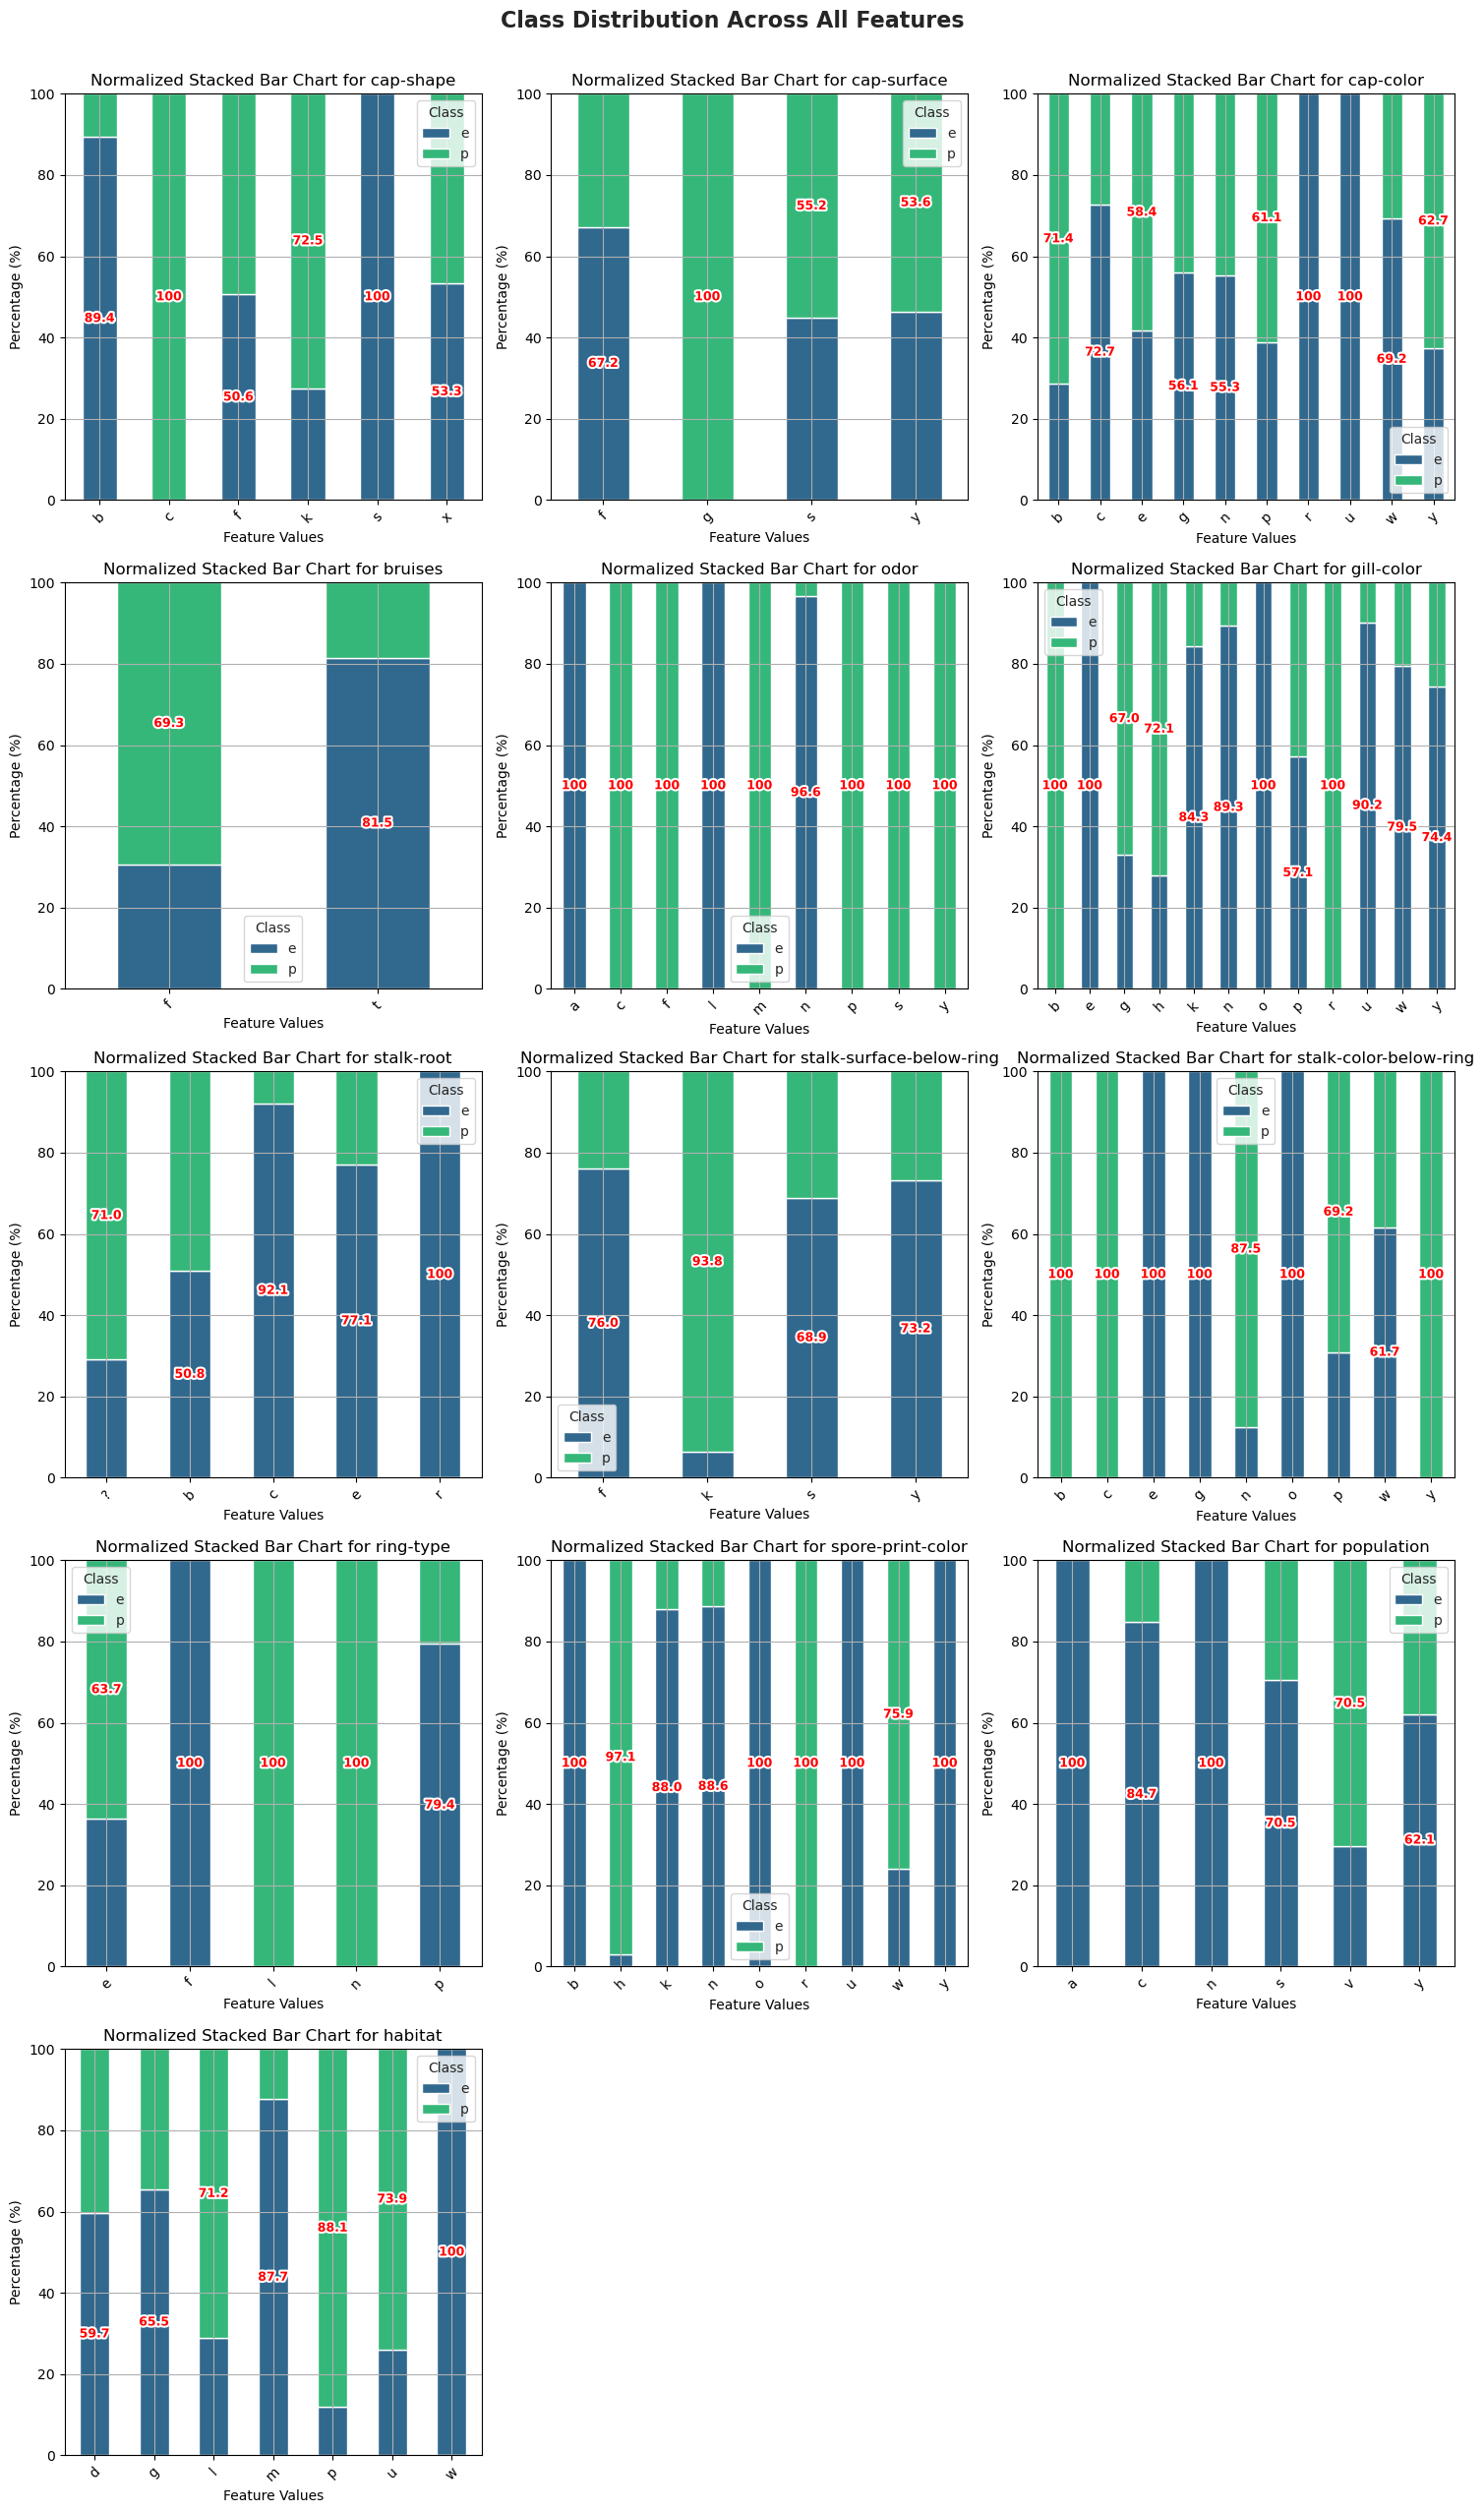

In [110]:
n_plots = len(possible_factors)
n_cols = 3
n_rows = (n_plots + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
axes = axes.flatten()
sns.set_style("whitegrid")
colors = sns.color_palette("viridis", 2)
for idx, given_feature in enumerate(possible_factors):
    ax = axes[idx]
    
    class_names = sorted(list(set(df['class'])))
    feature_names = sorted(list(set(df[given_feature])))
    cross_tab = pd.crosstab(df[given_feature], df['class'])
    cross_tab_norm = cross_tab.div(cross_tab.sum(axis=1), axis=0) * 100
    
    cross_tab_norm.plot(kind='bar', stacked=True, color=colors, ax=ax)
    ax.set_title(f'Normalized Stacked Bar Chart for {given_feature}')
    ax.set_xlabel('Feature Values')
    ax.set_ylabel('Percentage (%)')
    ax.legend(title='Class')
    ax.tick_params(axis='x', rotation=45)
    ax.set_ylim(0, 100)
    
    for container in ax.containers:
        labels = []
        for v in container.datavalues:
            if v == 100:
                labels.append(f'{int(v)}')
            elif v > 50:
                labels.append(f'{v:.1f}')
            else:
                labels.append('')
        label_objects = ax.bar_label(container, labels=labels, label_type='center', 
                                    fontsize=9, color='red', weight='bold')
        
        # Add white outline to each label
        for label in label_objects:
            if label.get_text():
                label.set_path_effects([
                    path_effects.Stroke(linewidth=3, foreground='white'),
                    path_effects.Normal()
                ])

for idx in range(n_plots, len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
fig.suptitle('Class Distribution Across All Features', fontsize=16, fontweight='bold', y=1.02)
plt.savefig('images/Class Distribution Across All Features.png')
plt.show()

Basic Observations:
1. Stalk-shape has almost equal distribution for both of its values
2. Bruises has a high tendency towards one class for each of its values.
3. Stalk-Surface-Above-Ring and Stalk-Surface-Below-Ring have similar plots.
4. Stalk-Color-Above-Ring and Stalk-Color-Below-Ring have similar plots.

Basic Hypotheses:
1. Stalk-shape has no say on the classes
2. Bruises has a strong effect on the classes
3. Stalk-Surface-Above-Ring & Stalk-Surface-Below-Ring are highly correlated features (only one of the two are needed for prediction)
4. Stalk-Color-Above-Ring & Stalk-Color-Below-Ring are highly correlated features (only one of the two are needed for prediction)

This is based on the distribution of the feature and the class

In [111]:
for given_feature in possible_factors:
    cross_tab = pd.crosstab(df1[given_feature], df1['class'])
    cross_tab_norm = cross_tab.div(cross_tab.sum(axis=1), axis=0) * 100
    cross_tab_norm.to_csv(f'data/tables/analysis/class_dist_per_feature_value_{given_feature}.csv')

In [ ]:
possible_factors.remove('stalk-shape')
possible_factors.remove('stalk-color-above-ring')
possible_factors.remove('stalk-surface-above-ring')
len(possible_factors)

In [113]:
df1[possible_factors + ['class']].to_csv('mushrooms_feature_sel2.csv', index=False)

In [114]:
df3 = pd.read_csv('mushrooms_feature_sel2.csv')

In [115]:
df3

,cap-shape,cap-surface,cap-color,bruises,odor,gill-color,stalk-root,stalk-surface-below-ring,stalk-color-below-ring,ring-type,spore-print-color,population,habitat,class
0,x,s,n,t,p,k,e,s,w,p,k,s,u,p
1,x,s,y,t,a,k,c,s,w,p,n,n,g,e
2,b,s,w,t,l,n,c,s,w,p,n,n,m,e
3,x,y,w,t,p,n,e,s,w,p,k,s,u,p
4,x,s,g,f,n,k,e,s,w,e,n,a,g,e
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8119,k,s,n,f,n,y,b,s,o,p,b,c,l,e
8120,x,s,n,f,n,y,b,s,o,p,b,v,l,e
8121,f,s,n,f,n,n,b,s,o,p,b,c,l,e
8122,k,y,n,f,y,b,b,k,w,e,w,v,l,p


#### Statistics about the data

In [40]:
# Define all feature importance calculation functions
def calculate_information_gain(df, feature, target):
    """Calculate Information Gain"""
    # Calculate entropy of target
    target_counts = df[target].value_counts()
    target_entropy = entropy(target_counts, base=2)
    
    # Calculate weighted entropy after split
    feature_values = df[feature].unique()
    weighted_entropy = 0
    total_samples = len(df)
    
    for value in feature_values:
        subset = df[df[feature] == value]
        subset_prob = len(subset) / total_samples
        subset_counts = subset[target].value_counts()
        subset_entropy = entropy(subset_counts, base=2) if len(subset_counts) > 1 else 0
        weighted_entropy += subset_prob * subset_entropy
    
    information_gain = target_entropy - weighted_entropy
    return information_gain

def calculate_mutual_information(df, feature, target):
    """Calculate Mutual Information using sklearn"""
    le_feature = LabelEncoder()
    le_target = LabelEncoder()
    
    feature_encoded = le_feature.fit_transform(df[feature])
    target_encoded = le_target.fit_transform(df[target])
    
    mi = mutual_info_classif(feature_encoded.reshape(-1, 1), target_encoded, 
                            discrete_features=True, random_state=42)[0]
    return mi

def calculate_chi_square(df, feature, target):
    """Calculate Chi-square test for independence"""
    cross_tab = pd.crosstab(df[feature], df[target])
    chi2, p_value, dof, expected = chi2_contingency(cross_tab)
    return chi2, p_value

def calculate_gini_reduction(df, feature, target):
    """Calculate Gini Impurity Reduction"""
    def gini_impurity(y):
        proportions = y.value_counts() / len(y)
        return 1 - sum(proportions**2)
    
    # Original Gini impurity
    original_gini = gini_impurity(df[target])
    
    # Weighted Gini after split
    feature_values = df[feature].unique()
    weighted_gini = 0
    total_samples = len(df)
    
    for value in feature_values:
        subset = df[df[feature] == value]
        subset_weight = len(subset) / total_samples
        subset_gini = gini_impurity(subset[target])
        weighted_gini += subset_weight * subset_gini
    
    gini_reduction = original_gini - weighted_gini
    return gini_reduction

def calculate_visual_metrics(cross_tab_norm):
    """Calculate visual metrics from normalized cross-tabulation"""
    class_1_proportions = cross_tab_norm.iloc[:, 1].values
    
    variance = np.var(class_1_proportions)
    range_val = np.max(class_1_proportions) - np.min(class_1_proportions)
    extreme_score = np.sum((class_1_proportions < 20) | (class_1_proportions > 80)) / len(class_1_proportions)
    
    return variance, range_val, extreme_score

In [41]:
features_to_analyze = possible_factors
results = []

In [42]:
print("FEATURE IMPORTANCE ANALYSIS")
print("=" * 80)
print(f"{'Feature':<10} {'Info Gain':<10} {'Mutual Info':<12} {'Chi2':<8} {'P-value':<10} {'Gini Red.':<10} {'Variance':<10} {'Range':<8} {'Extreme':<8}")
print("-" * 80)
for feature in features_to_analyze:
    # Statistical metrics
    info_gain = calculate_information_gain(df, feature, 'class')
    mutual_info = calculate_mutual_information(df, feature, 'class')
    chi2, p_value = calculate_chi_square(df, feature, 'class')
    gini_red = calculate_gini_reduction(df, feature, 'class')
    
    # Visual metrics from normalized stacked bar
    cross_tab = pd.crosstab(df[feature], df['class'])
    cross_tab_norm = cross_tab.div(cross_tab.sum(axis=1), axis=0) * 100
    variance, range_val, extreme_score = calculate_visual_metrics(cross_tab_norm)
    
    results.append({
        'feature': feature,
        'info_gain': info_gain,
        'mutual_info': mutual_info,
        'chi2': chi2,
        'p_value': p_value,
        'gini_reduction': gini_red,
        'variance': variance,
        'range': range_val,
        'extreme_score': extreme_score
    })
    
    print(f"{feature:<10} {info_gain:<10.3f} {mutual_info:<12.3f} {chi2:<8.1f} {p_value:<10.4f} {gini_red:<10.3f} {variance:<10.1f} {range_val:<8.1f} {extreme_score:<8.1f}")

FEATURE IMPORTANCE ANALYSIS
Feature    Info Gain  Mutual Info  Chi2     P-value    Gini Red.  Variance   Range    Extreme 
--------------------------------------------------------------------------------
cap-shape  0.049      0.034        489.9    0.0000     0.030      1165.7     100.0    0.5     
cap-surface 0.029      0.020        315.0    0.0000     0.019      601.1      67.2     0.2     
cap-color  0.036      0.025        387.6    0.0000     0.024      577.1      71.4     0.2     
bruises    0.192      0.133        2041.4   0.0000     0.126      646.5      50.9     0.5     
odor       0.906      0.628        7659.7   0.0000     0.471      2173.0     100.0    1.0     
gill-color 0.417      0.289        3765.7   0.0000     0.231      1258.7     100.0    0.6     
stalk-root 0.108      0.075        1059.1   0.0000     0.065      491.2      57.8     0.5     
stalk-surface-below-ring 0.272      0.188        2684.5   0.0000     0.165      834.5      69.8     0.2     
stalk-color-below-rin

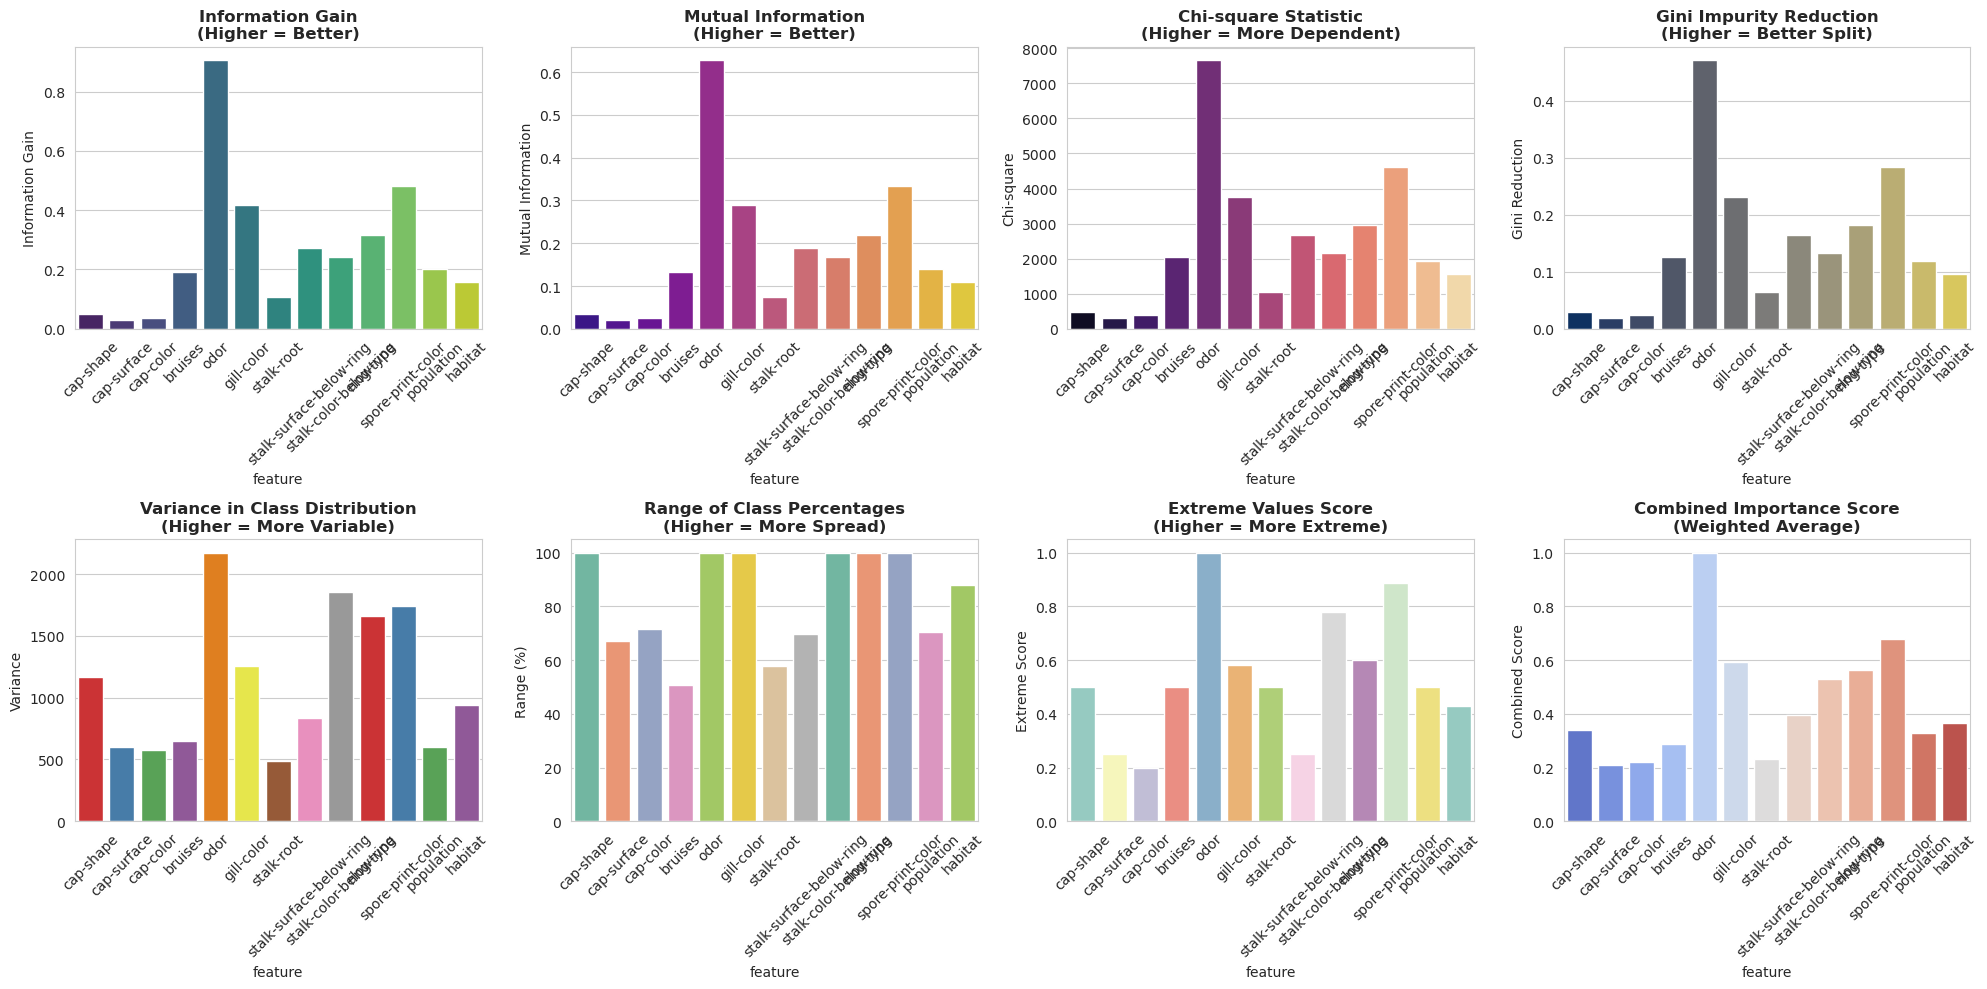

In [43]:
# Create visualization of the metrics
results_df = pd.DataFrame(results)

fig, axes = plt.subplots(2, 4, figsize=(20, 10))

# Plot 1: Information Gain
ax1 = axes[0, 0]
sns.barplot(data=results_df, x='feature', y='info_gain', palette='viridis', ax=ax1)
ax1.set_title('Information Gain\n(Higher = Better)', fontweight='bold')
ax1.set_ylabel('Information Gain')
ax1.tick_params(axis='x', rotation=45)

# Plot 2: Mutual Information
ax2 = axes[0, 1]
sns.barplot(data=results_df, x='feature', y='mutual_info', palette='plasma', ax=ax2)
ax2.set_title('Mutual Information\n(Higher = Better)', fontweight='bold')
ax2.set_ylabel('Mutual Information')
ax2.tick_params(axis='x', rotation=45)

# Plot 3: Chi-square statistic
ax3 = axes[0, 2]
sns.barplot(data=results_df, x='feature', y='chi2', palette='magma', ax=ax3)
ax3.set_title('Chi-square Statistic\n(Higher = More Dependent)', fontweight='bold')
ax3.set_ylabel('Chi-square')
ax3.tick_params(axis='x', rotation=45)

# Plot 4: Gini Reduction
ax4 = axes[0, 3]
sns.barplot(data=results_df, x='feature', y='gini_reduction', palette='cividis', ax=ax4)
ax4.set_title('Gini Impurity Reduction\n(Higher = Better Split)', fontweight='bold')
ax4.set_ylabel('Gini Reduction')
ax4.tick_params(axis='x', rotation=45)

# Plot 5: Variance
ax5 = axes[1, 0]
sns.barplot(data=results_df, x='feature', y='variance', palette='Set1', ax=ax5)
ax5.set_title('Variance in Class Distribution\n(Higher = More Variable)', fontweight='bold')
ax5.set_ylabel('Variance')
ax5.tick_params(axis='x', rotation=45)

# Plot 6: Range
ax6 = axes[1, 1]
sns.barplot(data=results_df, x='feature', y='range', palette='Set2', ax=ax6)
ax6.set_title('Range of Class Percentages\n(Higher = More Spread)', fontweight='bold')
ax6.set_ylabel('Range (%)')
ax6.tick_params(axis='x', rotation=45)

# Plot 7: Extreme Score
ax7 = axes[1, 2]
sns.barplot(data=results_df, x='feature', y='extreme_score', palette='Set3', ax=ax7)
ax7.set_title('Extreme Values Score\n(Higher = More Extreme)', fontweight='bold')
ax7.set_ylabel('Extreme Score')
ax7.tick_params(axis='x', rotation=45)

# Plot 8: Combined importance score
ax8 = axes[1, 3]
# Create a combined importance score (normalized)
results_df['combined_score'] = (
    (results_df['info_gain'] / results_df['info_gain'].max()) * 0.3 +
    (results_df['mutual_info'] / results_df['mutual_info'].max()) * 0.3 +
    (results_df['variance'] / results_df['variance'].max()) * 0.2 +
    (results_df['range'] / results_df['range'].max()) * 0.2
)

sns.barplot(data=results_df, x='feature', y='combined_score', palette='coolwarm', ax=ax8)
ax8.set_title('Combined Importance Score\n(Weighted Average)', fontweight='bold')
ax8.set_ylabel('Combined Score')
ax8.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('images/statistics_features.png')
plt.show()

In [ ]:
def analyze_feature_importance(df, feature_column, target_column):
    """Complete feature importance analysis function"""
    
    print(f"\n🔍 ANALYZING FEATURE: {feature_column}")
    print("=" * 50)
    
    # Create cross-tabulation
    cross_tab = pd.crosstab(df[feature_column], df[target_column])
    cross_tab_norm = cross_tab.div(cross_tab.sum(axis=1), axis=0) * 100
    
    # Calculate all metrics
    info_gain = calculate_information_gain(df, feature_column, target_column)
    mutual_info = calculate_mutual_information(df, feature_column, target_column)
    chi2, p_value = calculate_chi_square(df, feature_column, target_column)
    gini_red = calculate_gini_reduction(df, feature_column, target_column)
    variance, range_val, extreme_score = calculate_visual_metrics(cross_tab_norm)
    
    print(f"📊 Statistical Metrics:")
    print(f"   Information Gain: {info_gain:.3f}")
    print(f"   Mutual Information: {mutual_info:.3f}")
    print(f"   Chi-square: {chi2:.2f} (p-value: {p_value:.4f})")
    print(f"   Gini Reduction: {gini_red:.3f}")
    
    print(f"\n📈 Visual Metrics:")
    print(f"   Variance: {variance:.1f}")
    print(f"   Range: {range_val:.1f}%")
    print(f"   Extreme Score: {extreme_score:.2f}")
    
    # Interpretation
    print(f"\n💡 Interpretation:")
    if info_gain > 0.3 and variance > 100:
        print("   ✅ HIGHLY IMPORTANT feature for classification")
    elif info_gain > 0.1 and variance > 50:
        print("   🔶 MODERATELY IMPORTANT feature")
    elif info_gain > 0.05:
        print("   ⚠️ WEAKLY IMPORTANT feature")
    else:
        print("   ❌ UNIMPORTANT feature - consider removing")
    
    if p_value < 0.05:
        print(f"   📊 Statistically significant association (p < 0.05)")
    else:
        print(f"   📊 No significant association (p ≥ 0.05)")
    
    return {
        'info_gain': info_gain,
        'mutual_info': mutual_info,
        'chi2': chi2,
        'p_value': p_value,
        'gini_reduction': gini_red,
        'variance': variance,
        'range': range_val,
        'extreme_score': extreme_score
    }

# Analyze each feature
feature_results = {}
for feature in possible_factors:
    feature_results[feature] = analyze_feature_importance(df, feature, 'class')

# Create comparison visualization
print(f"\n🏆 FEATURE RANKING:")
print("=" * 30)

# Rank features by combined importance
ranking_data = []
for feature, metrics in feature_results.items():
    combined_score = (
        metrics['info_gain'] * 0.25 +
        metrics['mutual_info'] * 0.25 +
        (metrics['variance'] / 500) * 0.25 +  # Normalize variance
        (metrics['range'] / 100) * 0.25       # Normalize range
    )
    ranking_data.append({'feature': feature, 'score': combined_score})

ranking_df = pd.DataFrame(ranking_data).sort_values('score', ascending=False)

for i, row in ranking_df.iterrows():
    score = row['score']
    if score > 0.6:
        icon = "🥇"
    elif score > 0.4:
        icon = "🥈"
    else:
        icon = "🥉"
    print(f"   {icon} {row['feature']}: {score:.3f}")

Basic Hypotheses:
1. Cap-color, Cap-surface and Cap-shape have no say on the classes

In [45]:
possible_factors.remove('cap-color')
possible_factors.remove('cap-shape')
possible_factors.remove('cap-surface')
len(possible_factors)

10

### Final Verdict

Thus, we shall be using only the following 10 out of 22 features for further PCA analysis
1. bruises
2. odor
3. gill-color
4. stalk-root
5. stalk-surface-below-ring
6. stalk-color-below-ring
7. ring-type
8. spore-print-color
9. population
10. habitat

In [47]:
df = df[possible_factors + ['class']]

In [49]:
df.to_csv('mushrooms_cleaned.csv', index=False)

# PCA

## Why is PCA required?

Let us try to do the Logistic Regression as it is.

### Taking 10 features

In [23]:
df = pd.read_csv('mushrooms_cleaned.csv')

In [24]:
X = df.drop(columns=['class'])
y = df['class']

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

In [29]:
encoder = OneHotEncoder(sparse_output=False, drop='first')
encoder.fit(X_train)

OneHotEncoder(drop='first', sparse_output=False)

In [30]:
X_train_encoded = encoder.transform(X_train)
X_test_encoded = encoder.transform(X_test)

In [31]:
model = LogisticRegression()
model.fit(X_train_encoded, y_train)
y_pred = model.predict(X_test_encoded)

In [32]:
model.score(X_test_encoded, y_test)

0.999015263417036

### Taking 13 features

In [34]:
df = pd.read_csv('mushrooms_feature_sel1.csv')

In [35]:
X = df.drop(columns=['class'])
y = df['class']

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

In [37]:
encoder = OneHotEncoder(sparse_output=False, drop='first')
encoder.fit(X_train)

OneHotEncoder(drop='first', sparse_output=False)

In [38]:
X_train_encoded = encoder.transform(X_train)
X_test_encoded = encoder.transform(X_test)

In [39]:
model = LogisticRegression()
model.fit(X_train_encoded, y_train)
y_pred = model.predict(X_test_encoded)

In [40]:
model.score(X_test_encoded, y_test)

0.999015263417036

### Taking 16 features

In [41]:
df = pd.read_csv('mushrooms_feature_sel2.csv')

In [42]:
X = df.drop(columns=['class'])
y = df['class']

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

In [44]:
encoder = OneHotEncoder(sparse_output=False, drop='first')
encoder.fit(X_train)

OneHotEncoder(drop='first', sparse_output=False)

In [45]:
X_train_encoded = encoder.transform(X_train)
X_test_encoded = encoder.transform(X_test)

In [46]:
model = LogisticRegression()
model.fit(X_train_encoded, y_train)
y_pred = model.predict(X_test_encoded)

In [47]:
model.score(X_test_encoded, y_test)

0.999015263417036

### Taking all features

In [79]:
df = pd.read_csv('mushrooms_no_missing.csv')

In [81]:
X = df.drop(columns=['class'])
y = df['class']

In [82]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

In [83]:
encoder = OneHotEncoder(sparse_output=False, drop='first')
encoder.fit(X_train)

OneHotEncoder(drop='first', sparse_output=False)

In [84]:
X_train_encoded = encoder.transform(X_train)
X_test_encoded = encoder.transform(X_test)

In [85]:
model = LogisticRegression()
model.fit(X_train_encoded, y_train)
y_pred = model.predict(X_test_encoded)

In [86]:
model.score(X_test_encoded, y_test)

1.0

## Vanilla PCA

### Taking 10 features

In [88]:
df = pd.read_csv('mushrooms_cleaned.csv')

In [94]:
X = df.drop(columns=['class'])
y = df['class']

In [90]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

In [96]:
encoder = OneHotEncoder(sparse_output=False, drop='first')
X_train_encoded = encoder.fit_transform(X_train)

In [97]:
X_test_encoded = encoder.transform(X_test)

In [109]:
pipeline = Pipeline([
    ('encoder', OneHotEncoder(drop='first', sparse_output=False)),
    ('pca', PCA(n_components=2)),  # Optional
    ('classifier', LogisticRegression())
])

# Automatically handles the correct order
pipeline.fit(X_train, y_train)
accuracy = pipeline.score(X_test, y_test)

In [110]:
accuracy

0.8847858197932054

## Kernel PCA

# Final Results